In [ ]:
%pip install pandas scikit-learn matplotlib

In [ ]:
import pandas as pd

df = pd.read_csv("dermatology/dermatology.data", header=None, na_values="?")
# header=None: needs to be specified as pandas treats the first line of the file as col names.
# There are 8 missing values (see dermatology.names) in the col Age, each denoted as '?'.
# Because '?' becomes a special float value NaN, the rest of the col Age can be parsed 
# as numbers. Else (w/o na_values="?"): Age would be read as text (object).

print(df.shape)
cols = [
    "erythema", "scaling", "definite_borders", "itching", "koebner_phenomenon",
    "polygonal_papules", "follicular_papules", "oral_mucosal_involvement",
    "knee_elbow_involvement", "scalp_involvement", "family_history",
    "melanin_incontinence", "eosinophils_infiltrate", "pnl_infiltrate",
    "fibrosis_papillary_dermis", "exocytosis", "acanthosis", "hyperkeratosis",
    "parakeratosis", "clubbing_rete_ridges", "elongation_rete_ridges",
    "thinning_suprapapillary_epidermis", "spongiform_pustule", "munro_microabcess",
    "focal_hypergranulosis", "disappearance_granular_layer",
    "vacuolisation_basal_layer", "spongiosis", "saw_tooth_retes",
    "follicular_horn_plug", "perifollicular_parakeratosis",
    "inflammatory_mononuclear_infiltrate", "band_like_infiltrate",
    "age", "class",
]
print(f"Number of columns - {len(cols)}.\n")

df.columns = cols
print(df.head())

# Check against section 9 of dermatology.names: OBS. imbalanced data:
df["class"].value_counts().sort_index() 


Number of columns - 35.

   erythema  scaling  definite_borders  itching  koebner_phenomenon  \
0         2        2                 0        3                   0   
1         3        3                 3        2                   1   
2         2        1                 2        3                   1   
3         2        2                 2        0                   0   
4         2        3                 2        2                   2   

   polygonal_papules  follicular_papules  oral_mucosal_involvement  \
0                  0                   0                         0   
1                  0                   0                         0   
2                  3                   0                         3   
3                  0                   0                         0   
4                  2                   0                         2   

   knee_elbow_involvement  scalp_involvement  ...  \
0                       1                  0  ...   
1                    

class
1    112
2     61
3     72
4     49
5     52
6     20
Name: count, dtype: int64

In [112]:
# Instances where there is NaN in "Age":
print(df.loc[df["age"].isna(), "class"])

33     1
34     4
35     2
36     3
262    5
263    5
264    5
265    5
Name: class, dtype: int64


In [113]:
# Split features and target: .drop returns a new object:
X = df.drop(columns="class")
y = df["class"]

In [114]:
from sklearn.model_selection import train_test_split

# Split the data into a train dataset and a test dataset:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=6, stratify=y
)

print(X_train.shape, X_test.shape)

(292, 34) (74, 34)


In [115]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier

# Build a pipeline for imputing and classification:
model =Pipeline([
    ("impute", SimpleImputer (strategy="median")),
    ("tree", DecisionTreeClassifier(random_state=7))
])

model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('impute', ...), ('tree', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](6,)","[1,2,3,4,5,6]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](34,)","['erythema','scaling','definite_borders',..., 'inflammatory_mononuclear_infiltrate','band_like_infiltrate','age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,34
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurren

In [116]:
y_pred = model.predict(X_test)

from sklearn.metrics import accuracy_score, classification_report

# Compute metrics:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred))

Accuracy: 0.919
              precision    recall  f1-score   support

           1       0.96      1.00      0.98        23
           2       1.00      0.67      0.80        12
           3       0.94      1.00      0.97        15
           4       0.71      1.00      0.83        10
           5       1.00      0.90      0.95        10
           6       1.00      0.75      0.86         4

    accuracy                           0.92        74
   macro avg       0.94      0.89      0.90        74
weighted avg       0.94      0.92      0.92        74



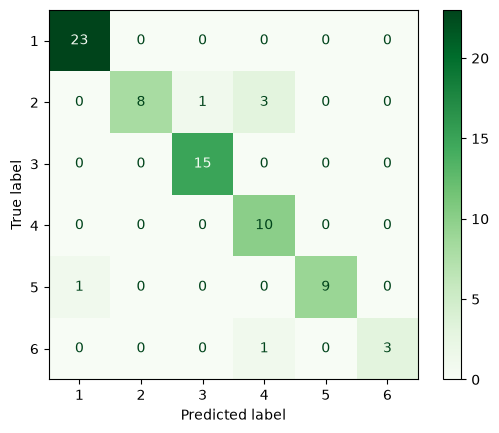

In [117]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap="Greens")

In [118]:
# For assessing overfitting:
model.score(X_train, y_train)   # Results: 1.0 (train) vs. 0.919 (test, above) => some overfitting

1.0

In [119]:
# The actual depth of unrestricted tree:
model.named_steps["tree"].get_depth()

12

In [ ]:
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold

# General Set-up (for Set-up 1 below):
# Hold out 20% of the data as test_data (stratified), train on the rest of the data.
# For each max_depth:
#   For train_data:
#       stratified 5-fold CV (5 fits), repeated 5 times (5 fits x 5 = 25 fits);
#       score of each fit = mean f1_score of f1_scores, wherein each f1_score is per class;
#       mean f1_score = mean of 25 validation f1 scores.
# Pick the max_depth with the best mean f1_score.
# Refit the best pipeline on whole training data, then evaluate on the test data.

# Set-up 1: param_grid = {"tree__max_depth": [2, 3, 4, 5, 6, 8, 10, None]}
# Findings: the tree needs depth 6 or above.
# Problem: leaves with very few samples, such as 1.
# Action: a parameter - min_samples_leaf - has also been passed into the grid model (see Set-up 2).


# Set-up 2:
param_grid = {
    "tree__max_depth": [5, 6, 8, None],
    "tree__min_samples_leaf": [1, 2, 3, 5]
    }

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=5)   # shuffles by default
print(cv.get_n_splits(X_train, y_train))    # n_splits = 25

grid = GridSearchCV(model, param_grid, cv=cv, scoring="f1_macro") # f1_macro - unweighted (w.r.t. classes) mean of f1 scores

grid.fit(X_train, y_train)

print(grid.best_params_, round(grid.best_score_, 3)) 

# print(grid.cv_results_.keys())
pd.DataFrame(grid.cv_results_)[["param_tree__max_depth", "param_tree__min_samples_leaf", "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False)

# Findings: each of None and depth 8 gives the same mean_test_score for min_samples_leaf=5,
# hence the tree never grows deeper than 8 once each leaf must hold at least 5 samples.

25
{'tree__max_depth': 8, 'tree__min_samples_leaf': 1} 0.948
dict_keys(['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'param_tree__max_depth', 'param_tree__min_samples_leaf', 'params', 'split0_test_score', 'split1_test_score', 'split2_test_score', 'split3_test_score', 'split4_test_score', 'split5_test_score', 'split6_test_score', 'split7_test_score', 'split8_test_score', 'split9_test_score', 'split10_test_score', 'split11_test_score', 'split12_test_score', 'split13_test_score', 'split14_test_score', 'split15_test_score', 'split16_test_score', 'split17_test_score', 'split18_test_score', 'split19_test_score', 'split20_test_score', 'split21_test_score', 'split22_test_score', 'split23_test_score', 'split24_test_score', 'mean_test_score', 'std_test_score', 'rank_test_score'])


,param_tree__max_depth,param_tree__min_samples_leaf,mean_test_score,std_test_score
8,8,1,0.948208,0.034001
9,8,2,0.942336,0.034941
10,8,3,0.938752,0.033702
4,6,1,0.938343,0.029114
12,None,1,0.938105,0.025004
13,None,2,0.937161,0.032541
5,6,2,0.937018,0.030195
6,6,3,0.936616,0.030164
14,None,3,0.935349,0.031005
11,8,5,0.931422,0.036185


In [121]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred))
print("Train accuracy:", round(best_model.score(X_train, y_train), 3))

              precision    recall  f1-score   support

           1       0.96      1.00      0.98        23
           2       0.89      0.67      0.76        12
           3       0.94      1.00      0.97        15
           4       0.77      1.00      0.87        10
           5       1.00      0.90      0.95        10
           6       1.00      0.75      0.86         4

    accuracy                           0.92        74
   macro avg       0.93      0.89      0.90        74
weighted avg       0.93      0.92      0.92        74

Train accuracy: 0.993


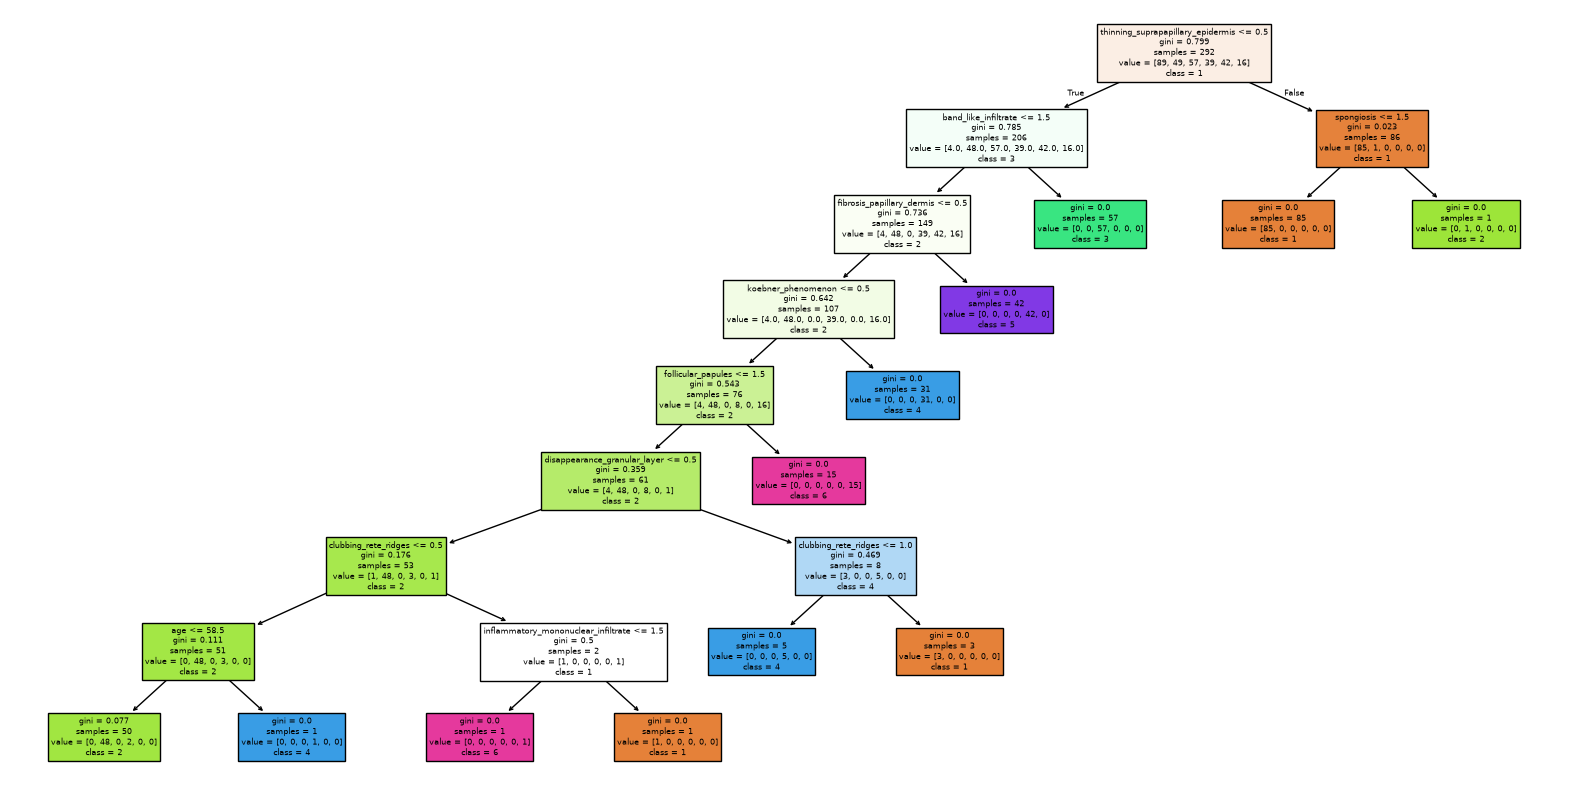

In [122]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))
plot_tree(best_model.named_steps["tree"], feature_names=X.columns,
          class_names=[str(c) for c in best_model.classes_], filled=True)
plt.show()

In [123]:
from sklearn.base import clone

# Setting chosen based on grid.cv_results of Set-up 2:
final_model = clone(model).set_params(tree__max_depth=6, tree__min_samples_leaf=3)
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

print("Train accuracy:", round(final_model.score(X_train, y_train), 3))
print("Test accuracy:", round(final_model.score(X_test, y_test), 3))

print(classification_report(y_test, y_pred))

# Motivation behind the choice of the final model:
# The final_model (depth 6, >= 3 samples/leaf) is simpler, shows less overfit and at least
# as accurate on the test data as the model (depth 8, >= 1 sample/leaf).

Train accuracy: 0.969
Test accuracy: 0.946
              precision    recall  f1-score   support

           1       0.96      1.00      0.98        23
           2       0.91      0.83      0.87        12
           3       0.94      1.00      0.97        15
           4       0.91      1.00      0.95        10
           5       1.00      0.90      0.95        10
           6       1.00      0.75      0.86         4

    accuracy                           0.95        74
   macro avg       0.95      0.91      0.93        74
weighted avg       0.95      0.95      0.94        74



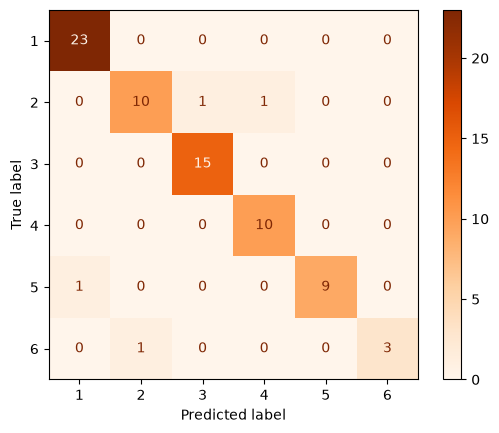

In [124]:
# Confusion matrix for the final model
ConfusionMatrixDisplay.from_estimator(final_model, X_test, y_test, cmap="Oranges")

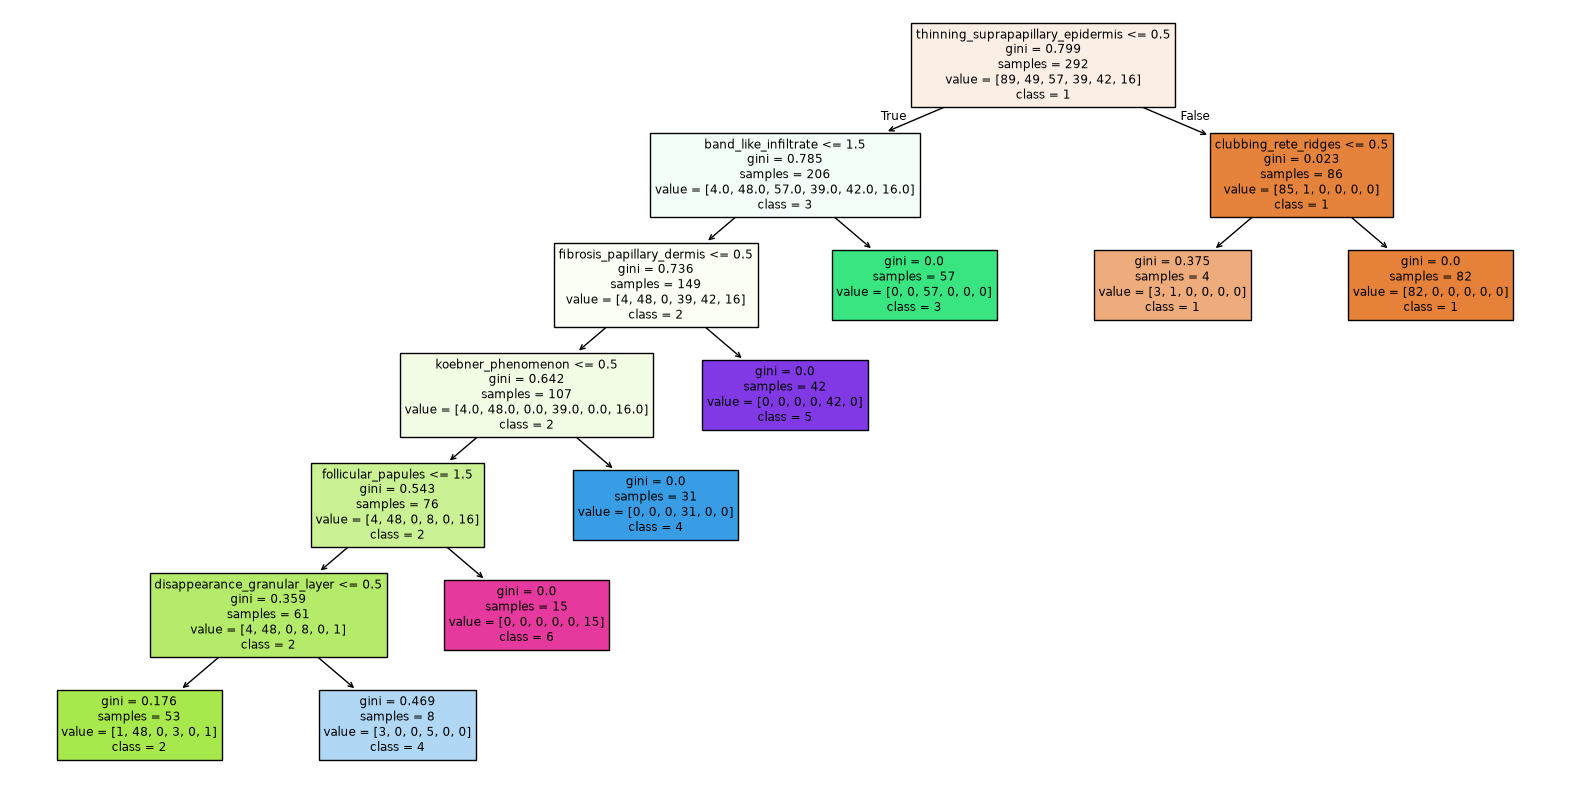

In [125]:
plt.figure(figsize=(20, 10))
plot_tree(final_model.named_steps["tree"], feature_names=X.columns,
          class_names=[str(c) for c in final_model.classes_], filled=True)
plt.show()

In [126]:
# Feature importance - how much each feature reduces impurity across the split
importance = pd.Series(final_model.named_steps["tree"].feature_importances_, index=X.columns)
print(importance.sort_values(ascending=False).head(7))

thinning_suprapapillary_epidermis    0.318260
band_like_infiltrate                 0.238144
fibrosis_papillary_dermis            0.187154
koebner_phenomenon                   0.125429
follicular_papules                   0.088479
disappearance_granular_layer         0.040356
clubbing_rete_ridges                 0.002179
dtype: float64
